In [2]:
import pandas as pd
import numpy as np
print('FRANX')

FRANX


In [3]:
df = pd.read_csv('laptop_data_practice_dirty.csv')
df

,laptop_id,model_name,release_year,price,battery_life_hrs,processor,ram_gb,storage,os,touchscreen,notes
0,LAP3013,HP Envy x360,2024,"""83,403""",10.3,NaN,8,512GB SSD,NaN,Yes,gaming build
1,LAP3022,Asus ROG Strix,2017,80755,9.4,AMD Ryzen 7,16,512GB SSD,Linux,Yes,NaN
2,LAP3047,Lenovo IdeaPad Slim 3,2023,30717 INR,7.3,AMD Ryzen 5,32,256GB SSD,Windows,No,NaN
3,LAP3067,Dell Inspiron 15,2021,131161,4.0,Intel i3,32,512GB HDD,Linux,No,gaming build
4,LAP3039,Acer Swift 3,2018,₹98287,7.4,Intel i3,8,256GB SSD,NaN,No,NaN
...,...,...,...,...,...,...,...,...,...,...,...
71,LAP3048,Dell Vostro 14,2019,64863,8.8,NaN,32,256GB SSD,Windows,Yes,gaming build
72,LAP3050,Lenovo Legion 5,2016,₹3132335,11.0,Intel i9,64,512GB SSD,macOS,Yes,NaN
73,LAP3055,Asus ROG Strix,2023,1646 INR,11.7,Intel i5,32,1TB SSD,Linux,No,office use ready
74,LAP3032,Lenovo Legion 5,2024,"""48,528""",NaN,Intel i7,8,256GB SSD,macOS,No,great battery life


In [4]:
df.head()

,laptop_id,model_name,release_year,price,battery_life_hrs,processor,ram_gb,storage,os,touchscreen,notes
0,LAP3013,HP Envy x360,2024,"""83,403""",10.3,NaN,8,512GB SSD,NaN,Yes,gaming build
1,LAP3022,Asus ROG Strix,2017,80755,9.4,AMD Ryzen 7,16,512GB SSD,Linux,Yes,NaN
2,LAP3047,Lenovo IdeaPad Slim 3,2023,30717 INR,7.3,AMD Ryzen 5,32,256GB SSD,Windows,No,NaN
3,LAP3067,Dell Inspiron 15,2021,131161,4.0,Intel i3,32,512GB HDD,Linux,No,gaming build
4,LAP3039,Acer Swift 3,2018,₹98287,7.4,Intel i3,8,256GB SSD,NaN,No,NaN


In [5]:
steps involved are 
-- null values removal
-- correction of data like price havinig """$2423""" (string) into integer 2423
-- duplicates
-- outliers
-- clean Text/Categorical Inconsistencies
"""need not to in order"""

SyntaxError: invalid syntax (3362190419.py, line 1)

In [ ]:
df.info()

In [ ]:
df['price'].unique()

In [ ]:
df['price'] = df['price'].str.replace('$', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)
df['price'] = df['price'].str.replace(' INR', '', regex=False)
df['price'] = df['price'].str.replace('₹', '', regex=False)
df['price'] = df['price'].str.replace('"', '', regex=False)
print("*")

In [ ]:
df['price'] = df['price'].fillna("0")

In [ ]:
df['price'].unique()

In [6]:
df['price'] = df['price'].astype(int)

ValueError: cannot convert float NaN to integer

In [ ]:
df['price'].unique()

In [ ]:
#selects all without any zeros
res = df[df['price'] != 0]['price']
print(res)
print(res.median())

In [ ]:
median_price = df[df['price'] != 0]['price'].median()
df['price'] = df['price'].replace(0,median_price)

In [ ]:
df['price'].unique()

In [ ]:
print(df['price'])

In [ ]:
df.info()

In [ ]:
#now battery_life_hrs
df['battery_life_hrs']

In [ ]:
df['battery_life_hrs'].isna().sum()

In [ ]:
df['battery_life_hrs'].unique()

In [ ]:
df['battery_life_hrs'].mode()

In [ ]:
#df[df['battery_life_hrs'] == 8.6]
#for cheking we are gettingg 6 mode values for battery life take median

In [ ]:
df['battery_life_hrs'].median()

In [ ]:
df['battery_life_hrs'] = df['battery_life_hrs'].fillna(df['battery_life_hrs'].median())

In [ ]:
df.info()

In [ ]:
df['processor'].head()

In [ ]:
# 100% take mode
df['processor'].mode()

In [ ]:
df['processor'] = df['processor'].fillna(df['processor'].mode()[0])

In [7]:
df['processor'].isna().sum()

np.int64(7)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_id         76 non-null     str    
 1   model_name        76 non-null     str    
 2   release_year      76 non-null     int64  
 3   price             72 non-null     str    
 4   battery_life_hrs  71 non-null     float64
 5   processor         69 non-null     str    
 6   ram_gb            76 non-null     int64  
 7   storage           76 non-null     str    
 8   os                61 non-null     str    
 9   touchscreen       76 non-null     str    
 10  notes             49 non-null     str    
dtypes: float64(1), int64(2), str(8)
memory usage: 11.4 KB


In [9]:
finally left os

SyntaxError: invalid syntax (4020195054.py, line 1)

In [ ]:
df['os'].unique()

In [ ]:
df['os'].mode()

In [ ]:
df['os'] = df['os'].fillna(df['os'].mode()[0])

In [ ]:
df['os'].isna().sum()

In [ ]:
df['notes']

In [ ]:
df['notes'] = df['notes'].fillna('no notes')

In [ ]:
df.info()

In [ ]:
#finally check for duplicates
df.duplicated().sum()

In [ ]:
df[df['laptop_id'].duplicated()==1]

In [ ]:
df[df.duplicated()==1]

In [ ]:
df[df['laptop_id'].duplicated(keep=False)].sort_values('laptop_id')

In [ ]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [ ]:
"""
Why add reset_index(drop=True) too?
When you drop rows, pandas keeps the original index numbers — so your row labels will have gaps 
(e.g., 0, 1, 3, 4, 7... instead of 0, 1, 2, 3, 4...). That's not wrong, but it can cause confusion later 
(e.g., if you loop by position, or merge with another DataFrame). reset_index(drop=True) renumbers rows 
cleanly from 0 again. The drop=True part means "don't keep the old index as a new column" — try it without
drop=True once just to see what happens, so you understand why it's there.
"""

In [ ]:
df

In [ ]:
print(df.shape)          # row count should now be lower than before
print(df.duplicated().sum())   # should be 0

In [ ]:
#finally outliers to remove 

In [ ]:
#check
df['storage'].unique()

In [ ]:
#chheck
df['touchscreen'].unique()

In [ ]:
#outliers check in price and battery life

In [ ]:
df['price'].unique()

In [ ]:
df['price'].describe()

In [ ]:
#IQR METHOD REMOVING OUTLIER

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

In [ ]:
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
print(outliers[['laptop_id', 'price']])

In [ ]:
#the above two are outliers

In [ ]:
# Option A: Remove them
df = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
print("*")

In [ ]:
# Option B: Cap them at the bounds instead of removing (keeps row count)
df['price'] = df['price'].clip(lower=lower_bound, upper=upper_bound)
print("*")

In [ ]:
#final sanity check

In [ ]:
df.info()
df.describe()

In [ ]:
#as you can see that min in price is 614 so use brlow method
#you could use this method also

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(df['ram_gb'], df['price'])
plt.xlabel('RAM (GB)')
plt.ylabel('Price')
plt.title('Price vs RAM')
plt.show()

In [ ]:
#using domain knowleedge keeping 5000 as min

In [ ]:
df = df[df['price'] >= 5000]
df = df.reset_index(drop=True)
df['price'].min()   # confirm this is now >= 5000

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(df['ram_gb'], df['price'])
plt.xlabel('RAM (GB)')
plt.ylabel('Price')
plt.title('Price vs RAM')
plt.show()

In [ ]:
#checking this also
plt.figure(figsize=(8,5))
plt.scatter(df['battery_life_hrs'], df['price'])
plt.xlabel('Battery Life (hrs)')
plt.ylabel('Price')
plt.title('Price vs Battery Life')
plt.show()

In [ ]:
#leniar regression
import seaborn as sns
import matplotlib.pyplot as plt
print("*")

In [ ]:
df_encoded = pd.get_dummies(df, columns=['processor', 'os', 'touchscreen', 'storage'], drop_first=True)
df_encoded.head()

In [ ]:
X = df_encoded.drop(columns=['price', 'laptop_id', 'model_name', 'notes'])
y = df_encoded['price']

In [ ]:
X.columns

In [ ]:
import sklearn.model_selection as sms
X_train, X_test, y_train, y_test = sms.train_test_split(X, y, test_size=0.2, random_state=42)
#or down 

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

In [1]:
#correlation to check any more to drop
"""numeric_cols = ['release_year', 'price', 'battery_life_hrs', 'ram_gb'] + \
    [col for col in df_encoded.columns if col.startswith('processor_') 
     or col.startswith('os_') 
     or col.startswith('touchscreen_') 
     or col.startswith('storage_')]"""

corr = df_encoded.corr()
corr

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

NameError: name 'df_encoded' is not defined

In [189]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[-4814.11, -82.38, -62.64,...,16368.37,20147.4 ,16116.75]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['release_year','battery_life_hrs','ram_gb',...,'storage_256GB SSD', 'storage_512GB HDD','storage_512GB SSD']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.801e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,15


In [195]:
y_pred = model.predict(X_test) 
print("*")

*


In [196]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 22761.6849151258
MSE: 930332430.0584335
RMSE: 30501.351282499494
R² Score: 0.2523271536934031


In [200]:
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
#comparison_df.head(10)
comparison_df

,Actual,Predicted
61,64863,118032.885822
57,83644,56578.717703
0,83403,94753.363597
43,64841,52029.314339
5,123626,95136.437959
36,58373,87090.525575
16,74967,83972.075691
12,59360,62146.047686
25,142007,98447.610905
60,147091,145818.573281


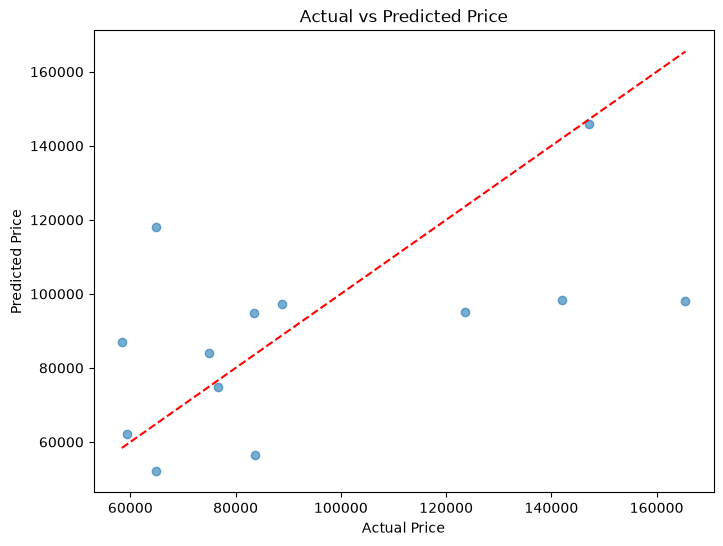

In [198]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # perfect prediction line
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()